In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import networkx as nx
import os
import warnings
warnings.filterwarnings('ignore')

BASE   = r'D:\FYP\Eco-Twin'
V2_DIR = os.path.join(BASE, 'v2_clean')

STATIONS_EXCEL   = os.path.join(V2_DIR, 'Delhi_list_v2.xlsx')
DATASET_CSV      = os.path.join(V2_DIR, 'EcoTwin_Final_Dataset.csv')
STATIC_ADJ_PATH  = os.path.join(V2_DIR, 'static_adj_matrix.npy')
DYNAMIC_ADJ_PATH = os.path.join(V2_DIR, 'dynamic_adj_matrix.npy')
THRESHOLD_KM     = 12.0

print(f"v2 dir : {V2_DIR}")
print(f"Threshold : {THRESHOLD_KM} km")
print("Imports OK.")

v2 dir : D:\FYP\Eco-Twin\v2_clean
Threshold : 12.0 km
Imports OK.


In [2]:
df_stations = pd.read_excel(STATIONS_EXCEL)
df_stations.columns = df_stations.columns.str.strip().str.lower()
df_stations['station'] = df_stations['station'].str.strip()

station_names = df_stations['station'].tolist()
lats = df_stations['latitude'].values
lons = df_stations['longitude'].values
N    = len(station_names)

df = pd.read_csv(DATASET_CSV, parse_dates=['Timestamp'])
df['Station'] = df['Station'].str.strip()
df = df.sort_values(['Station', 'Timestamp']).reset_index(drop=True)

print(f"Stations : {N}")
print(f"Rows     : {len(df):,}")
print(f"Hours    : {df['Timestamp'].nunique():,}")
print(f"Date     : {df['Timestamp'].min()} -> {df['Timestamp'].max()}")

assert 'u_wind' in df.columns and 'v_wind' in df.columns, "Wind columns missing!"

# name consistency
excel_set, data_set = set(station_names), set(df['Station'].unique())
if excel_set == data_set:
    print("✓ Station names match between Excel and dataset.")
else:
    print(f"⚠ Mismatch: {excel_set ^ data_set}")

Stations : 37
Rows     : 737,077
Hours    : 19,921
Date     : 2024-01-01 00:00:00 -> 2026-04-10 00:00:00
✓ Station names match between Excel and dataset.


In [3]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi    = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)
    a = np.sin(dphi/2)**2 + np.cos(phi1)*np.cos(phi2)*np.sin(dlambda/2)**2
    return 2 * R * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

dist_matrix = np.zeros((N, N))
for i in range(N):
    for j in range(N):
        if i != j:
            dist_matrix[i, j] = haversine_km(lats[i], lons[i], lats[j], lons[j])

within_threshold = (dist_matrix > 0) & (dist_matrix <= THRESHOLD_KM)

dir_u = np.zeros((N, N))
dir_v = np.zeros((N, N))
for i in range(N):
    for j in range(N):
        if i != j:
            d_east  = (lons[j] - lons[i]) * np.cos(np.radians(lats[i]))
            d_north = (lats[j] - lats[i])
            norm = np.sqrt(d_east**2 + d_north**2)
            if norm > 0:
                dir_u[i, j] = d_east / norm
                dir_v[i, j] = d_north / norm

print(f"Pairs within {THRESHOLD_KM} km : {within_threshold.sum()}")
print(f"Direction check dir_u[0,1]={dir_u[0,1]:.3f} vs -dir_u[1,0]={-dir_u[1,0]:.3f}")

Pairs within 12.0 km : 508
Direction check dir_u[0,1]=-0.510 vs -dir_u[1,0]=-0.510


In [4]:
def compute_At(u_winds, v_winds, within_threshold, dir_u, dir_v, dist_matrix, epsilon=1e-6):
    N = len(u_winds)
    A = np.zeros((N, N), dtype=np.float32)
    for i in range(N):
        for j in range(N):
            if not within_threshold[i, j]:
                continue
            alignment = u_winds[i]*dir_u[i, j] + v_winds[i]*dir_v[i, j]
            if alignment > 0:
                A[i, j] = alignment / (dist_matrix[i, j] + epsilon)
    row_sums = A.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    return A / row_sums

# unit test
u_t = np.array([1.0, 0.0]); v_t = np.array([0.0, 0.0])
wt = np.array([[False, True],[True, False]])
du = np.array([[0,1.0],[-1.0,0]]); dv = np.zeros((2,2))
dm = np.array([[0,5.0],[5.0,0]])
A_t = compute_At(u_t, v_t, wt, du, dv, dm)
assert A_t[0,1] > 0 and A_t[1,0] == 0
print("✓ compute_At defined and unit test passed.")

✓ compute_At defined and unit test passed.


In [5]:
import time
timestamps = sorted(df['Timestamp'].unique())
T = len(timestamps)
station_index = {name: i for i, name in enumerate(station_names)}

print(f"Computing A(t) for {T:,} timestamps × {N} stations...")
all_At = np.zeros((T, N, N), dtype=np.float32)
t0 = time.time()

# faster: pre-pivot wind into arrays
u_wide = df.pivot_table(index='Timestamp', columns='Station', values='u_wind').reindex(columns=station_names)
v_wide = df.pivot_table(index='Timestamp', columns='Station', values='v_wind').reindex(columns=station_names)
u_arr_all = u_wide.values  # (T, N)
v_arr_all = v_wide.values

for t_idx in range(T):
    u_arr = np.nan_to_num(u_arr_all[t_idx])
    v_arr = np.nan_to_num(v_arr_all[t_idx])
    all_At[t_idx] = compute_At(u_arr, v_arr, within_threshold, dir_u, dir_v, dist_matrix)
    if (t_idx+1) % 2000 == 0 or t_idx == T-1:
        print(f"  [{t_idx+1:>6,}/{T:,}]  {time.time()-t0:.0f}s")

np.save(DYNAMIC_ADJ_PATH, all_At)
print(f"\n✓ Saved {DYNAMIC_ADJ_PATH}")
print(f"  Shape {all_At.shape}, {all_At.nbytes/1e6:.1f} MB")
assert all_At.min() >= 0 and all_At.max() <= 1.001
print(f"  Range [{all_At.min():.4f}, {all_At.max():.4f}]  ✓")

Computing A(t) for 19,921 timestamps × 37 stations...
  [ 2,000/19,921]  2s
  [ 4,000/19,921]  4s
  [ 6,000/19,921]  6s
  [ 8,000/19,921]  7s
  [10,000/19,921]  9s
  [12,000/19,921]  10s
  [14,000/19,921]  11s
  [16,000/19,921]  13s
  [18,000/19,921]  15s
  [19,921/19,921]  16s

✓ Saved D:\FYP\Eco-Twin\v2_clean\dynamic_adj_matrix.npy
  Shape (19921, 37, 37), 109.1 MB
  Range [0.0000, 1.0000]  ✓


In [6]:
static_adj = np.load(STATIC_ADJ_PATH).astype(float)
np.fill_diagonal(static_adj, 0)
static_edges = int((static_adj > 0).sum())
dyn_edges = (all_At > 0).sum(axis=(1,2))
survival = dyn_edges.mean() / static_edges * 100

print(f"Static edges        : {static_edges}")
print(f"Dynamic mean/hour   : {dyn_edges.mean():.1f}")
print(f"Dynamic min/max     : {dyn_edges.min()} / {dyn_edges.max()}")
print(f"Survival rate       : {survival:.1f}%")
if 20 <= survival <= 75:
    print("✓ Survival rate reasonable.")
else:
    print("⚠ Check survival rate.")

Static edges        : 508
Dynamic mean/hour   : 259.6
Dynamic min/max     : 216 / 306
Survival rate       : 51.1%
✓ Survival rate reasonable.


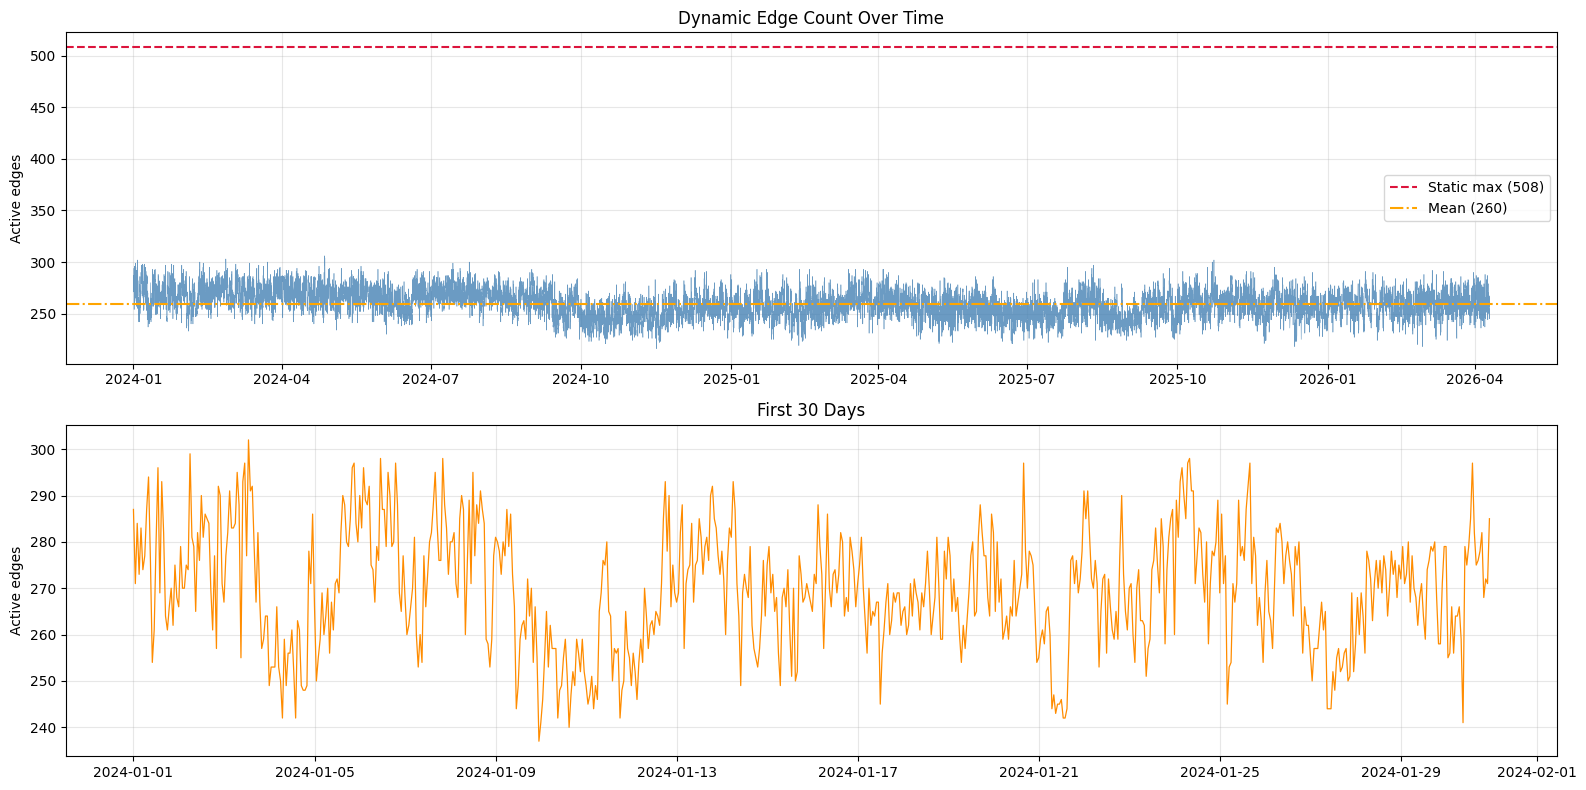

✓ Saved dyn_edge_count.png


In [7]:
ts_index = pd.DatetimeIndex(timestamps)
fig, axes = plt.subplots(2, 1, figsize=(16, 8))
axes[0].plot(ts_index, dyn_edges, lw=0.4, color='steelblue', alpha=0.8)
axes[0].axhline(static_edges, color='crimson', ls='--', label=f'Static max ({static_edges})')
axes[0].axhline(dyn_edges.mean(), color='orange', ls='-.', label=f'Mean ({dyn_edges.mean():.0f})')
axes[0].set_title('Dynamic Edge Count Over Time'); axes[0].set_ylabel('Active edges')
axes[0].legend(); axes[0].grid(True, alpha=0.3)
n_zoom = min(24*30, T)
axes[1].plot(ts_index[:n_zoom], dyn_edges[:n_zoom], lw=0.9, color='darkorange')
axes[1].set_title('First 30 Days'); axes[1].set_ylabel('Active edges'); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(V2_DIR, 'dyn_edge_count.png'), dpi=150, bbox_inches='tight')
plt.show()
print("✓ Saved dyn_edge_count.png")

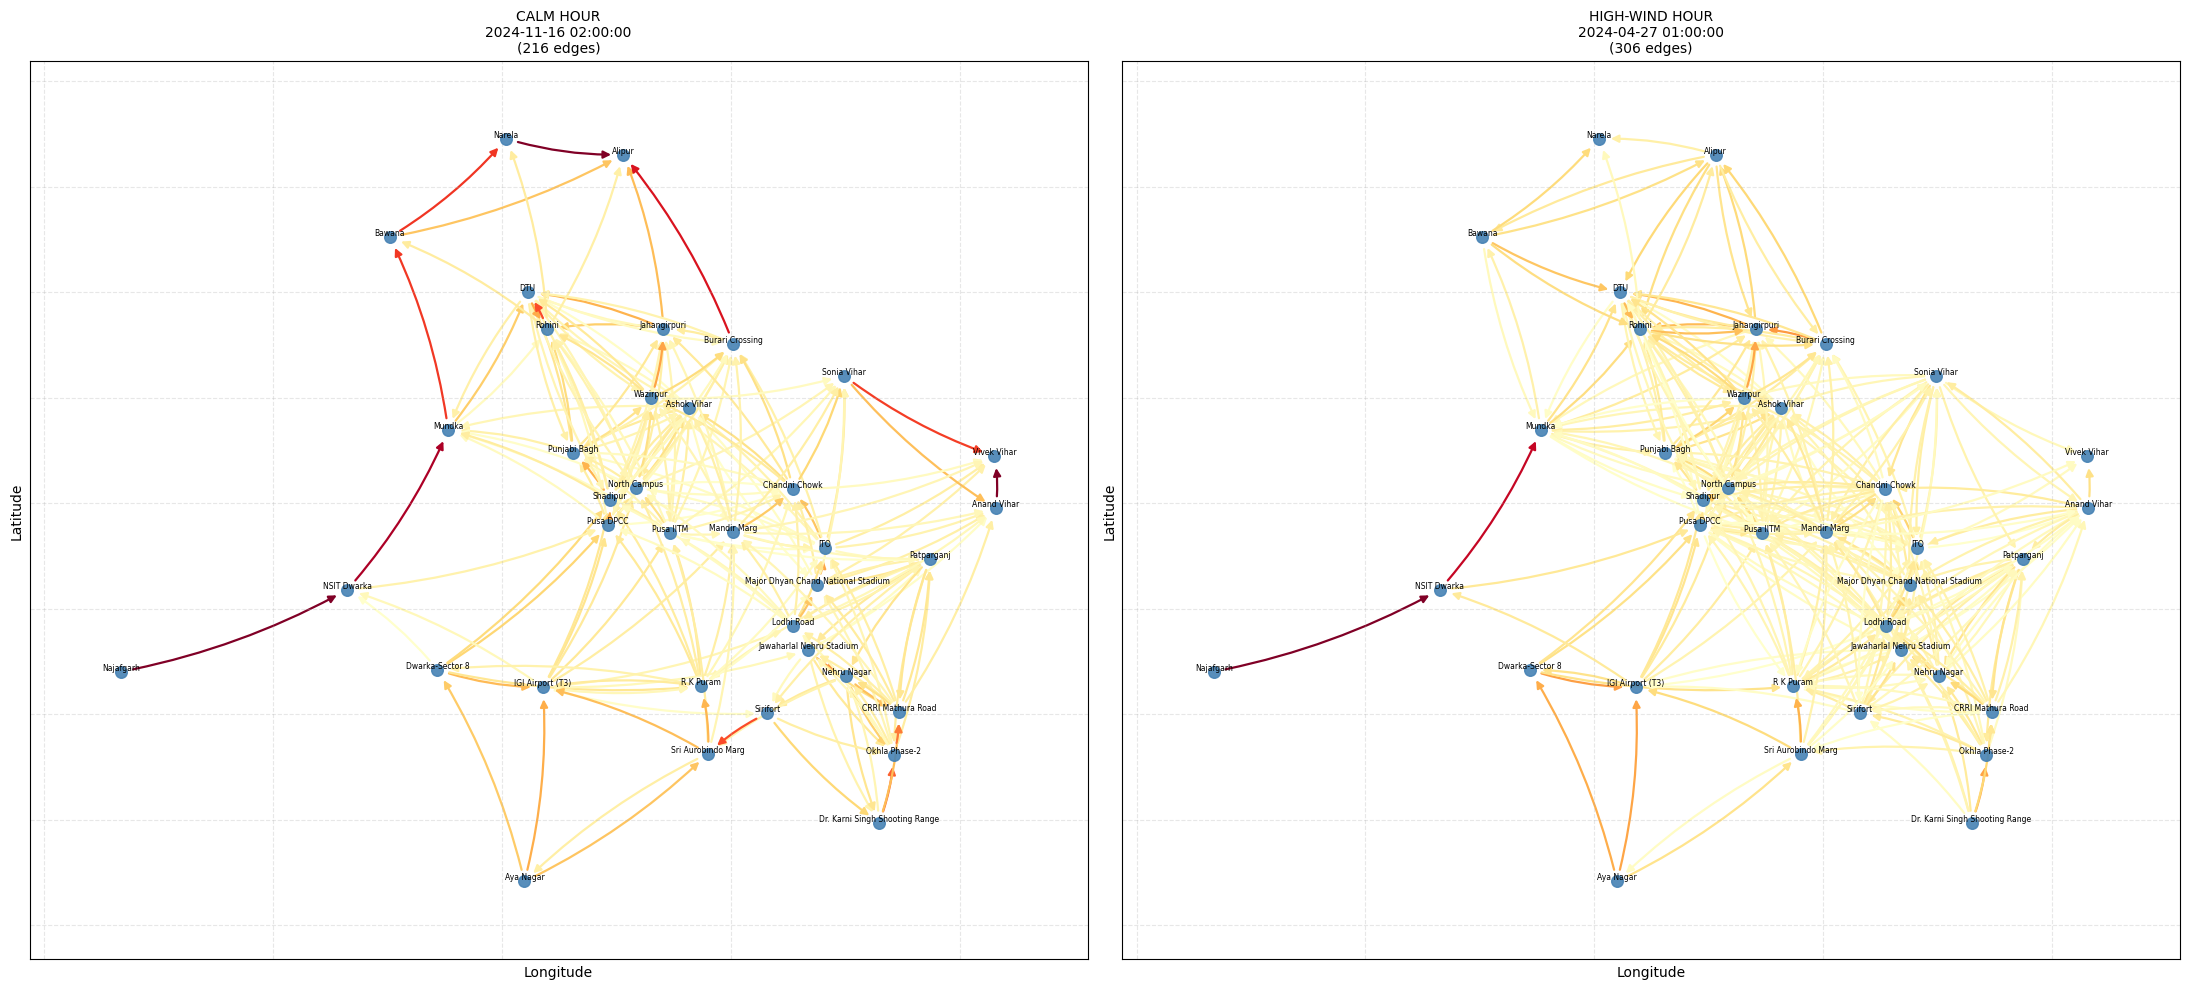

✓ Saved dyn_calm_vs_highwind.png


In [8]:
calm_idx = int(np.argmin(dyn_edges)); high_idx = int(np.argmax(dyn_edges))
pos = {i: (lons[i], lats[i]) for i in range(N)}

def draw_At(ax, A, ts, title):
    G = nx.DiGraph(); G.add_nodes_from(range(N))
    edges, weights = [], []
    for i in range(N):
        for j in range(N):
            if A[i,j] > 0:
                G.add_edge(i,j); edges.append((i,j)); weights.append(A[i,j])
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=70, node_color='steelblue', alpha=0.9)
    if edges:
        norm = mcolors.Normalize(0, max(weights)); cmap = cm.get_cmap('YlOrRd')
        nx.draw_networkx_edges(G, pos, ax=ax, edgelist=edges,
                               edge_color=[cmap(norm(w)) for w in weights],
                               width=1.6, arrows=True, arrowsize=11,
                               connectionstyle='arc3,rad=0.08')
    nx.draw_networkx_labels(G, pos, ax=ax, labels={i:station_names[i] for i in range(N)},
                            font_size=5.5, verticalalignment='bottom')
    ax.set_title(f"{title}\n{ts}\n({len(edges)} edges)", fontsize=10)
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.grid(True, ls='--', alpha=0.3)

fig, axes = plt.subplots(1, 2, figsize=(22, 10))
draw_At(axes[0], all_At[calm_idx], timestamps[calm_idx], "CALM HOUR")
draw_At(axes[1], all_At[high_idx], timestamps[high_idx], "HIGH-WIND HOUR")
plt.tight_layout()
plt.savefig(os.path.join(V2_DIR, 'dyn_calm_vs_highwind.png'), dpi=200, bbox_inches='tight')
plt.show()
print("✓ Saved dyn_calm_vs_highwind.png")

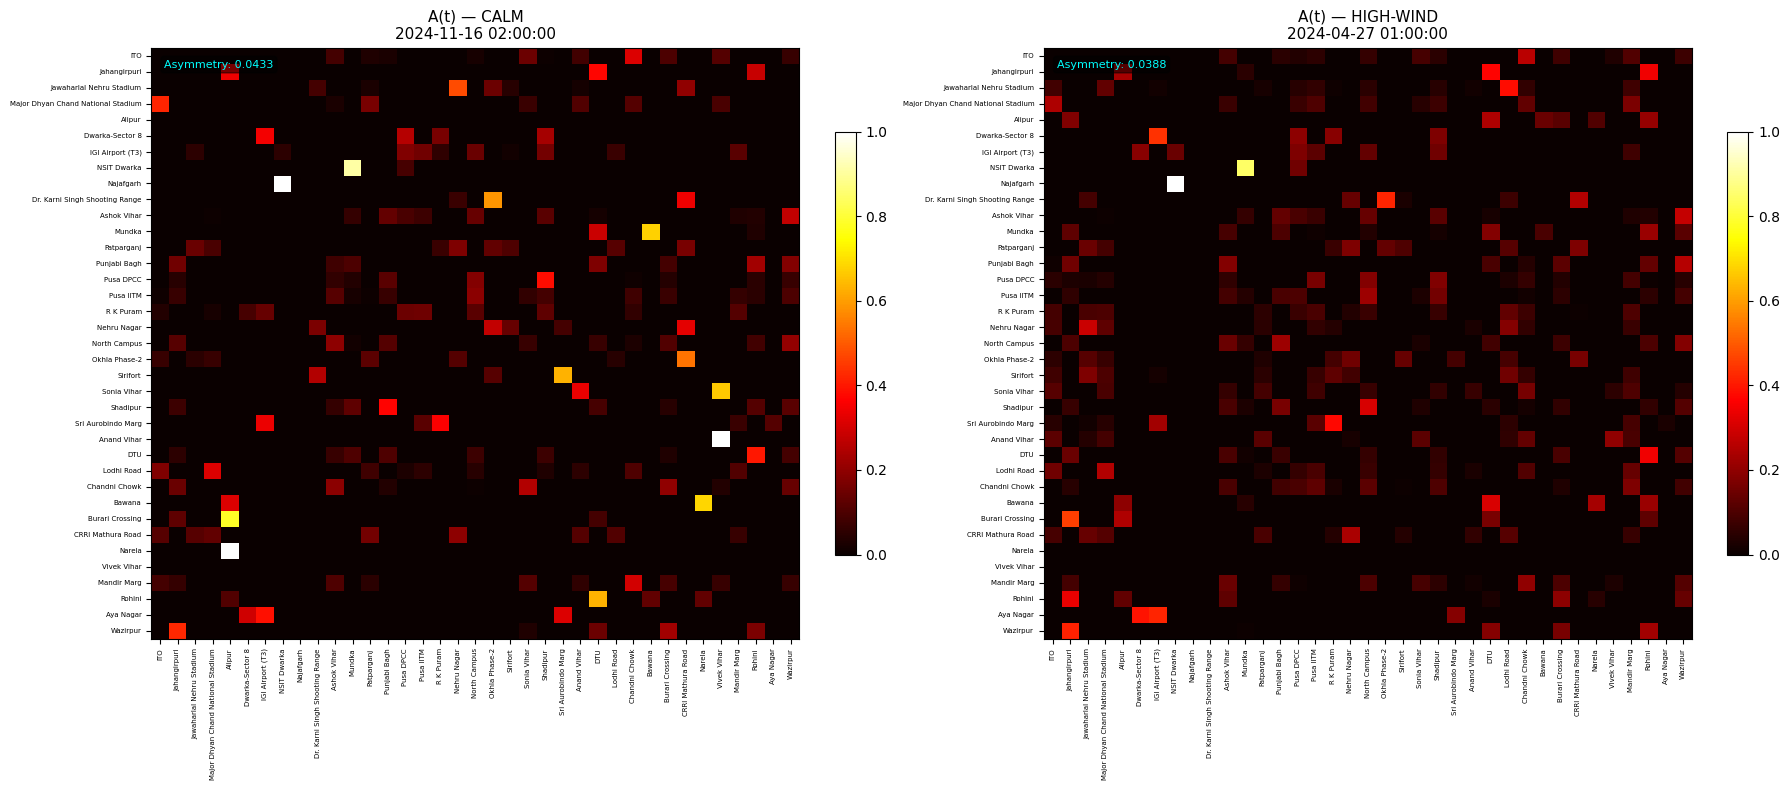

✓ Saved dyn_heatmap.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, idx, lbl in [(axes[0], calm_idx, 'CALM'), (axes[1], high_idx, 'HIGH-WIND')]:
    mat = all_At[idx]
    im = ax.imshow(mat, cmap='hot', vmin=0, vmax=mat.max() or 1, aspect='auto')
    ax.set_title(f"A(t) — {lbl}\n{timestamps[idx]}", fontsize=11)
    ax.set_xticks(range(N)); ax.set_yticks(range(N))
    ax.set_xticklabels(station_names, rotation=90, fontsize=5)
    ax.set_yticklabels(station_names, fontsize=5)
    plt.colorbar(im, ax=ax, fraction=0.03)
    sym = np.mean(np.abs(mat - mat.T))
    ax.text(0.02, 0.98, f"Asymmetry: {sym:.4f}", transform=ax.transAxes,
            fontsize=8, va='top', color='cyan',
            bbox=dict(boxstyle='round', facecolor='black', alpha=0.5))
plt.tight_layout()
plt.savefig(os.path.join(V2_DIR, 'dyn_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()
print("✓ Saved dyn_heatmap.png")

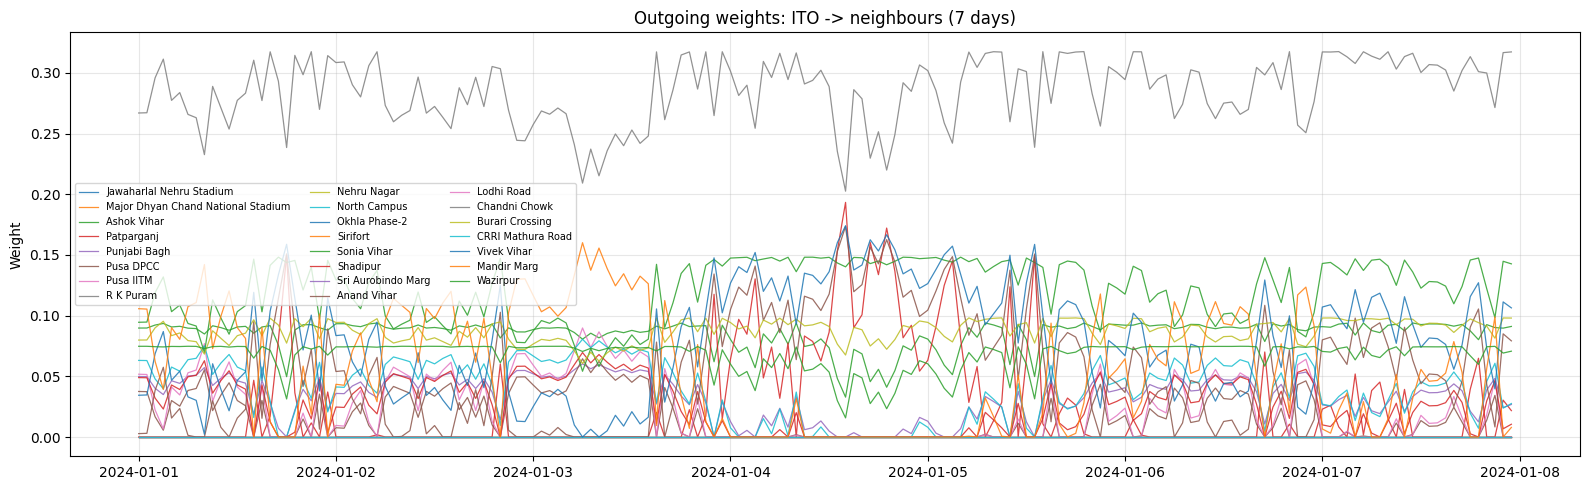

✓ Saved dyn_station_focus.png


In [10]:
focus = station_names[0]; f_idx = station_index[focus]
np.fill_diagonal(static_adj, 0)
neighs = np.where(static_adj[f_idx] > 0)[0]
n_hours = min(24*7, T)

fig, ax = plt.subplots(figsize=(16, 5))
for j in neighs:
    ax.plot(ts_index[:n_hours], all_At[:n_hours, f_idx, j], lw=0.9, alpha=0.85, label=station_names[j])
ax.set_title(f"Outgoing weights: {focus} -> neighbours (7 days)")
ax.set_ylabel("Weight"); ax.legend(fontsize=7, ncol=3); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(V2_DIR, 'dyn_station_focus.png'), dpi=150, bbox_inches='tight')
plt.show()
print("✓ Saved dyn_station_focus.png")

In [11]:
print("="*55)
print("  DYNAMIC ADJACENCY COMPLETE (v2_clean)")
print("="*55)
print(f"  Saved   : {DYNAMIC_ADJ_PATH}")
print(f"  Shape   : {all_At.shape}")
print(f"  Static edges     : {static_edges}")
print(f"  Dynamic mean/hr  : {dyn_edges.mean():.1f}")
print(f"  Survival rate    : {survival:.1f}%")
print(f"  Weight range     : [{all_At.min():.4f}, {all_At.max():.4f}]")
print("\n  NEXT: 04_feature_engineering.ipynb")
print("="*55)

  DYNAMIC ADJACENCY COMPLETE (v2_clean)
  Saved   : D:\FYP\Eco-Twin\v2_clean\dynamic_adj_matrix.npy
  Shape   : (19921, 37, 37)
  Static edges     : 508
  Dynamic mean/hr  : 259.6
  Survival rate    : 51.1%
  Weight range     : [0.0000, 1.0000]

  NEXT: 04_feature_engineering.ipynb
